<a href="https://colab.research.google.com/github/Bindiya-Anand/StreamFlix-Content-Analytics-Project/blob/main/notebooks/StreamFlix_Phase2_EDA_Bindiya_Anand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Internmo Data Analytics Project
## StreamFlix Content Analysis
### Data Analyst Intern: Bindiya Anand
#### Intern Id: Inter563

# Phase 2: Exploratory Data Analysis

## Importing necessary libraries

In [1]:
# Importing necessary libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Loading Datasets

In [2]:
subs = pd.read_csv("subscribers.csv")
titles = pd.read_csv("titles.csv")
watch = pd.read_csv("watch_history.csv", parse_dates=["watch_date"])
reviews = pd.read_csv("reviews.csv")

print("subscribers:", subs.shape)
print("titles:", titles.shape)
print("watch_history:", watch.shape)
print("reviews:", reviews.shape)

subscribers: (15000, 14)
titles: (9000, 21)
watch_history: (135470, 10)
reviews: (35072, 7)


/tmp/ipykernel_2171/2749730818.py:3: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  watch = pd.read_csv("watch_history.csv", parse_dates=["watch_date"])


In [55]:
# join sessions with title info and subscriber info
df = watch.merge(titles[["title_id", "type", "primary_genre"]], on="title_id", how="left")
df = df.merge(subs[["subscriber_id", "country", "age"]], on="subscriber_id", how="left")

# ensure watch_date is datetime
df["watch_date"] = pd.to_datetime(df["watch_date"], errors="coerce")

df["watch_hours"] = df["watch_duration_min"] / 60
df["year"] = df["watch_date"].dt.year
df["month"] = df["watch_date"].dt.month
df["year_month"] = df["watch_date"].dt.to_period("M")

display(df.head())

,watch_id,subscriber_id,title_id,watch_date,device,region,content_duration_min,watch_duration_min,completion_pct,completed,type,primary_genre,country,age,watch_hours,year,month,year_month
0,1,SUB107630,TTL205207,2024-01-01,Smart TV,East Asia,888.0,826.7,93.1,True,TV Show,Comedy,South Korea,39,13.778333,2024.0,1.0,2024-01
1,2,SUB114773,TTL204889,2025-10-18,Mobile,South Asia,2340.0,1866.4,79.8,False,TV Show,Drama,India,44,31.106667,2025.0,10.0,2025-10
2,3,SUB106013,TTL206882,2026-04-26,Mobile,Latin America,656.0,75.0,11.4,False,TV Show,Comedy,Brazil,21,1.250000,2026.0,4.0,2026-04
3,4,SUB100939,TTL208849,2026-03-09,Mobile,North America,500.0,493.2,98.6,True,TV Show,Horror,United States,22,8.220000,2026.0,3.0,2026-03
4,5,SUB107223,TTL202529,2023-12-27,Tablet,North America,141.0,94.6,67.1,False,Movie,Action,United States,29,1.576667,2023.0,12.0,2023-12


## Chart 1 - Monthly viewing volume (sessions per month)

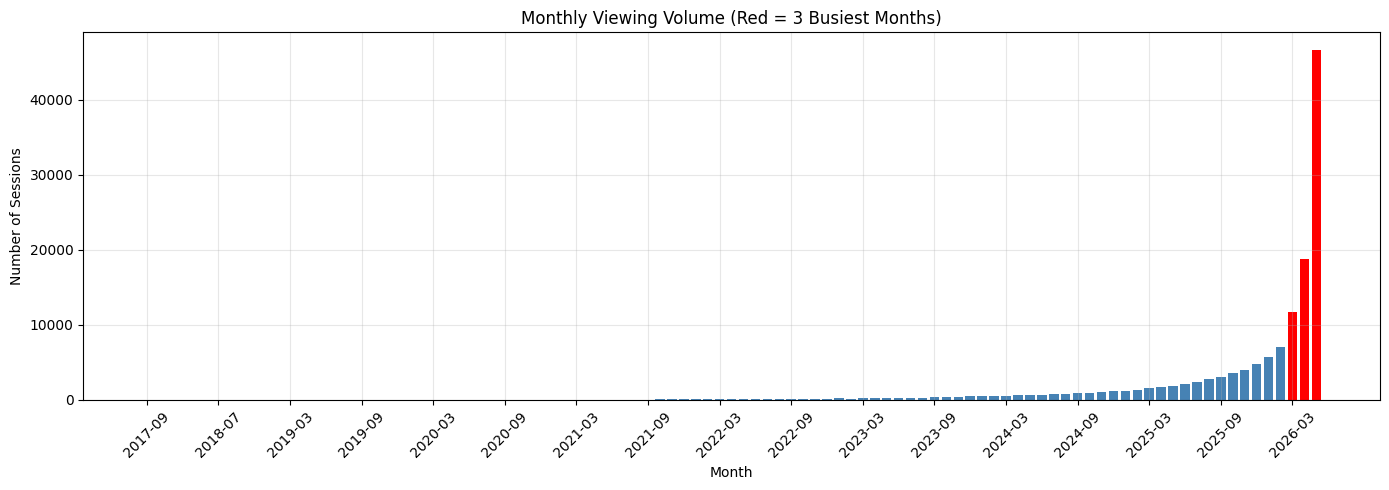

Busiest 3 months:
year_month
2026-05    46617
2026-04    18750
2026-03    11697
Freq: M, Name: count, dtype: int64


In [14]:
# count sessions in each month
sessions = df["year_month"].value_counts().sort_index()

# busiest 3 months get a red bar, others blue
top3 = sessions.nlargest(3).index
colors = []
for m in sessions.index:
    if m in top3:
        colors.append("red")
    else:
        colors.append("steelblue")

plt.figure(figsize=(14, 5))
plt.bar(range(len(sessions)), sessions.values, color=colors)
plt.xticks(range(0, len(sessions), 6), [str(m) for m in sessions.index[::6]], rotation=45)
plt.title("Monthly Viewing Volume (Red = 3 Busiest Months)")
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.grid(alpha=0.3)

plt.savefig("01_monthly_sessions.png", dpi=150)
plt.show()

print("Busiest 3 months:")
print(sessions.nlargest(3))

Observation:

>1.Monthly Viewing Volume
<br>
May 2026 recorded the highest number of viewing sessions (46,617), followed by April 2026 (18,750). Viewing activity increased sharply in the latest months shown, so check whether the dataset has uneven monthly coverage.

## Chart 2 - Monthly watch hours trend (year-over-year)

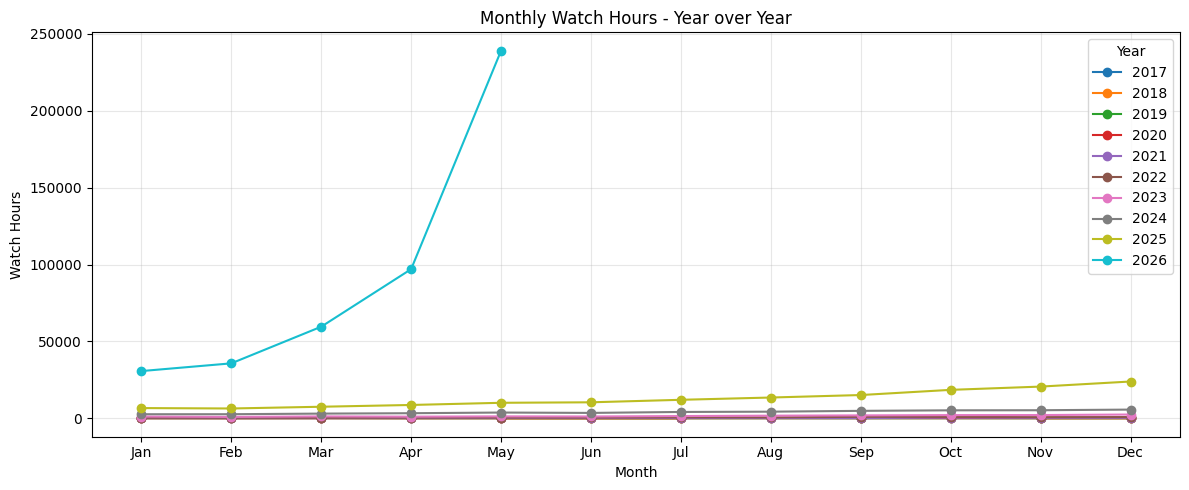

Total watch hours per year:
year
2017.0         2
2018.0       101
2019.0       433
2020.0       959
2021.0      3168
2022.0      7594
2023.0     18804
2024.0     48587
2025.0    153682
2026.0    461977
Name: watch_hours, dtype: int64


In [60]:
# total watch hours for each month-number (1-12) and each year
hours = df.pivot_table(index="month", columns="year", values="watch_hours", aggfunc="sum")

plt.figure(figsize=(12, 5))
for year in hours.columns:
    plt.plot(hours.index, hours[year], marker="o", label=int(year))

plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.title("Monthly Watch Hours - Year over Year")
plt.xlabel("Month")
plt.ylabel("Watch Hours")
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("02_monthly_watch_hours_yoy.png", dpi=150)
plt.show()

print("Total watch hours per year:")
print(df.groupby("year")["watch_hours"].sum().round(0))

Observation:

>2.Monthly Watch Hours Trend
<br>
Recorded viewing activity rises substantially over the years, with the largest totals in 2025 and 2026. However, these years may contain more records or incomplete periods, so the increase should not automatically be interpreted as growth in viewer engagement.

## Chart 3 - Genre-wise watch hours share

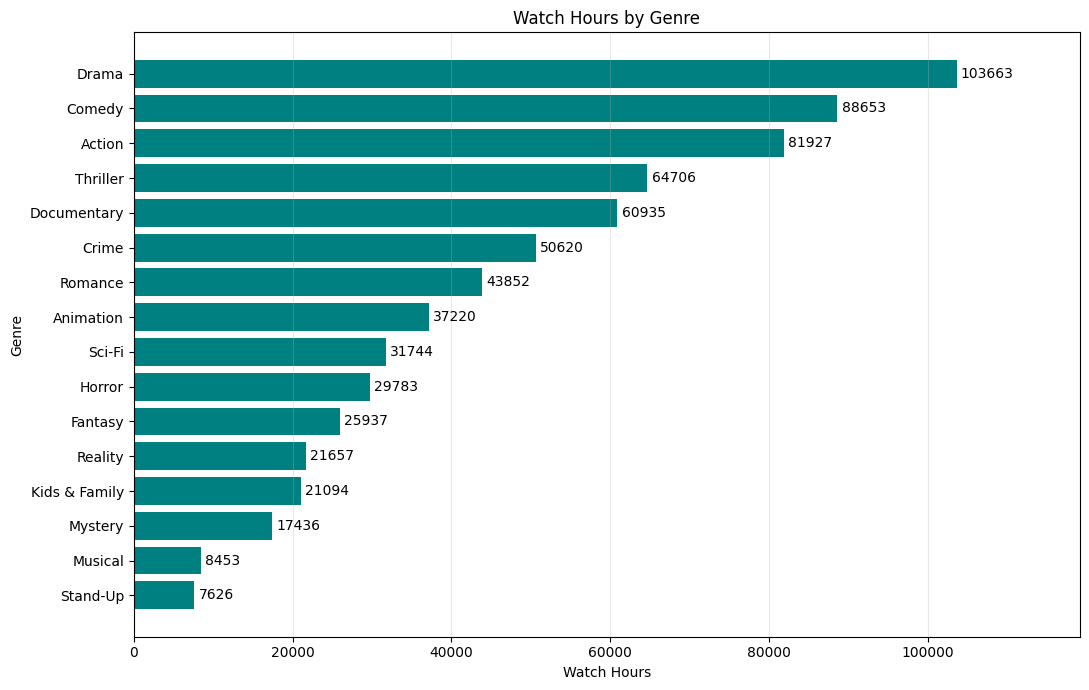

Share of total watch hours (%):
primary_genre
Drama            14.9
Comedy           12.8
Action           11.8
Thriller          9.3
Documentary       8.8
Crime             7.3
Romance           6.3
Animation         5.4
Sci-Fi            4.6
Horror            4.3
Fantasy           3.7
Reality           3.1
Kids & Family     3.0
Mystery           2.5
Musical           1.2
Stand-Up          1.1
Name: watch_hours, dtype: float64


In [57]:
genre_hours = df.groupby("primary_genre")["watch_hours"].sum().sort_values()

plt.figure(figsize=(11, 7))
bars = plt.barh(genre_hours.index, genre_hours.values, color="teal")
plt.title("Watch Hours by Genre")
plt.xlabel("Watch Hours")
plt.ylabel("Genre")

# Adding data labels
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.xlim(0, genre_hours.max() * 1.15)

plt.tight_layout()
plt.grid(axis="x", alpha=0.3)

plt.savefig("03_genre_watch_hours.png", dpi=150)
plt.show()

print("Share of total watch hours (%):")
print((genre_hours / genre_hours.sum() * 100).round(1).sort_values(ascending=False))

Observation
>3.Genre-wise Watch Time
<br>
Drama contributes the largest share of viewing time (14.9%), followed by Comedy (12.8%) and Action (11.8%). Musical and Stand-Up have the smallest shares, suggesting lower overall viewing demand for these genres in this dataset.

## Chart 4 - Content type split (Movies vs TV Shows)

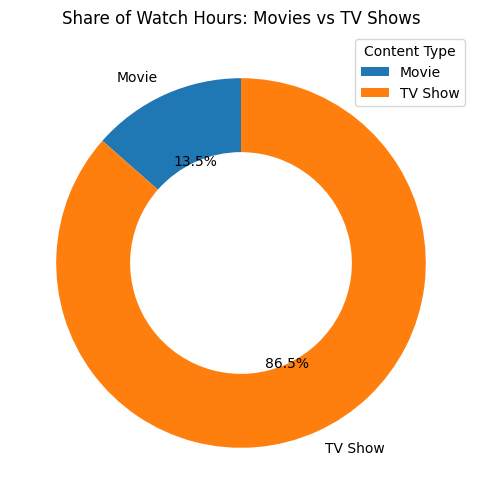

Watch Hours:
type
Movie       93857.0
TV Show    601450.0
Name: watch_hours, dtype: float64


In [58]:
type_hours = df.groupby("type")["watch_hours"].sum()

plt.figure(figsize=(6, 6))
# wedgeprops width makes the pie a donut
plt.pie(type_hours.values, labels=type_hours.index, autopct="%1.1f%%",
        startangle=90, wedgeprops={"width": 0.4})
plt.title("Share of Watch Hours: Movies vs TV Shows")
plt.legend(title="Content Type")
plt.savefig("04_content_type_donut.png", dpi=150)
plt.show()

print("Watch Hours:")
print(type_hours.round(0))

Observation
>4.Movies vs. TV Shows
<br>
TV Shows account for approximately 86.5% of recorded viewing duration, while Movies account for about 13.5%. TV Shows are the main source of viewing activity on the platform.

## Chart 5 - Top 10 countries by watch hours

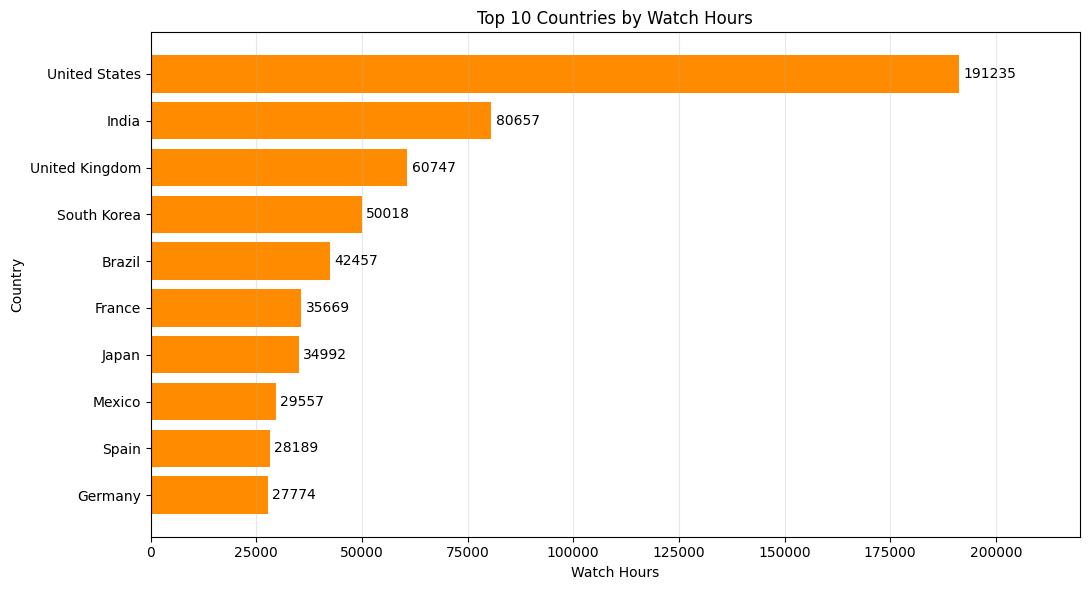

country
United States     191235.0
India              80657.0
United Kingdom     60747.0
South Korea        50018.0
Brazil             42457.0
France             35669.0
Japan              34992.0
Mexico             29557.0
Spain              28189.0
Germany            27774.0
Name: watch_hours, dtype: float64


In [61]:
top_countries = df.groupby("country")["watch_hours"].sum().nlargest(10).sort_values()

plt.figure(figsize=(11, 6))
bars = plt.barh(top_countries.index, top_countries.values, color="darkorange")
plt.title("Top 10 Countries by Watch Hours")
plt.xlabel("Watch Hours")
plt.ylabel("Country")

# Adding data labels
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.xlim(0, top_countries.max() * 1.15)

plt.tight_layout()
plt.grid(axis="x", alpha=0.3)
plt.savefig("05_top10_countries.png", dpi=150)
plt.show()

print(top_countries.sort_values(ascending=False).round(0))

Observation
>5.Top 10 Countries by Watch Time
<br>
The United States has the highest recorded viewing duration, followed by India and the United Kingdom. These countries appear to be important markets for StreamFlix and may deserve closer attention when planning content.

## Chart 6 - Subscriber plan distribution

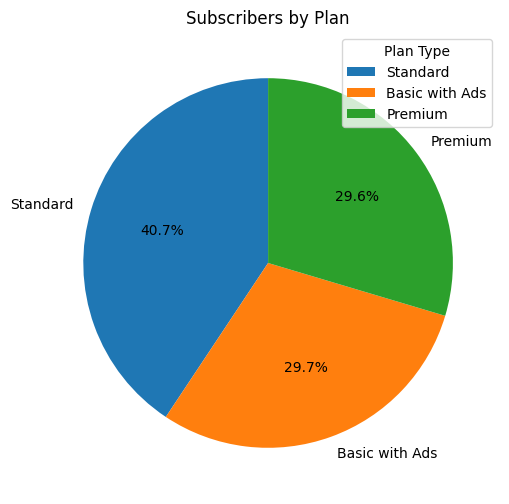

plan_type
Standard          6100
Basic with Ads    4458
Premium           4442
Name: count, dtype: int64


In [27]:
plan_counts = subs["plan_type"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(plan_counts.values, labels=plan_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Subscribers by Plan")
plt.legend(title="Plan Type")
plt.savefig("06_plan_distribution.png", dpi=150)
plt.show()

print(plan_counts)

Observation
>6.Subscriber Plan Distribution
<br>
Standard is the most common plan, with 6,100 subscribers. Basic with Ads and Premium have similar subscriber counts, suggesting that the subscriber base is spread across all three plans.

## Chart 7 - Device usage

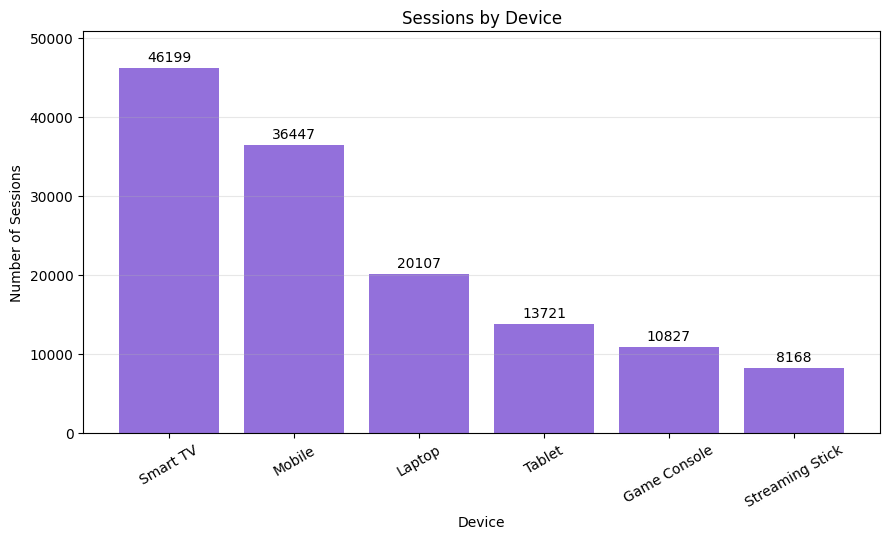

device
Smart TV           46199
Mobile             36447
Laptop             20107
Tablet             13721
Game Console       10827
Streaming Stick     8168
Name: count, dtype: int64


In [31]:
device_sessions = df["device"].value_counts()

plt.figure(figsize=(9, 5.5))
bars = plt.bar(device_sessions.index, device_sessions.values, color="mediumpurple")
plt.title("Sessions by Device")
plt.xlabel("Device")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)

# Adding data labels
plt.bar_label(bars, fmt="%d", padding=3)
plt.ylim(0, device_sessions.max() * 1.1)

plt.tight_layout()
plt.grid(axis="y", alpha=0.3)
plt.savefig("07_device_usage.png", dpi=150)
plt.show()

print(device_sessions)

Observation
>7.Device Usage
<br>
Smart TVs account for the most viewing sessions (46,199), followed by Mobile devices (36,447). StreamFlix should continue to provide a smooth viewing experience on both devices.

## Chart 8 - Age distribution of subscribers

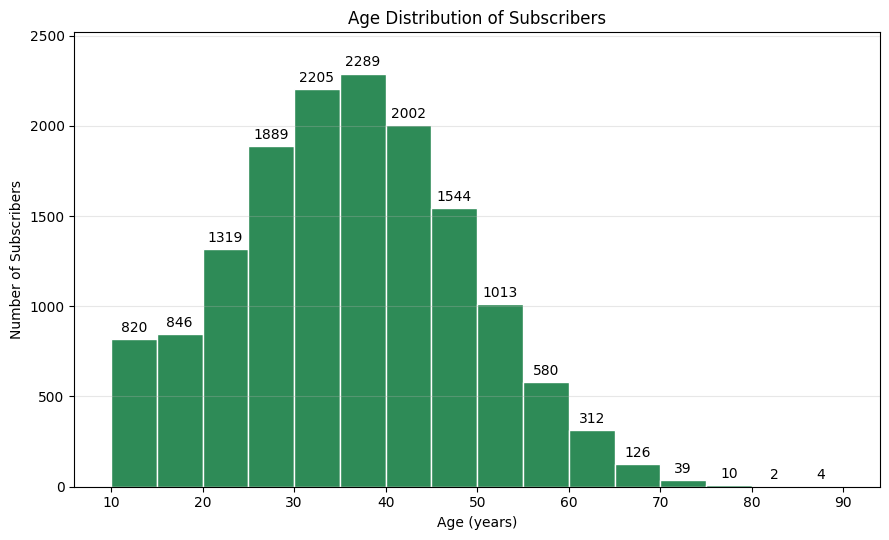

           subscribers  total_watch_hours  hours_per_subscriber
age_group                                                      
13-17             1270            57457.3                  45.2
18-24             1715            74701.8                  43.6
25-34             4094           188000.7                  45.9
35-44             4291           201232.8                  46.9
45-54             2557           125529.0                  49.1
55-64              892            40889.4                  45.8
65+                181             7495.4                  41.4


In [35]:
plt.figure(figsize=(9, 5.5))
counts, bins, bars = plt.hist(subs["age"], bins=range(10, 95, 5), color="seagreen", edgecolor="white")
plt.title("Age Distribution of Subscribers")
plt.xlabel("Age (years)")
plt.ylabel("Number of Subscribers")

# Adding data labels at top center of each bin
plt.bar_label(bars, fmt="%d", padding=3)
plt.ylim(0, counts.max() * 1.1)

plt.tight_layout()
plt.grid(axis="y", alpha=0.3)
plt.savefig("08_age_distribution.png", dpi=150)
plt.show()

# which age group watches the most?
age_bins = [12, 17, 24, 34, 44, 54, 64, 100]
age_labels = ["13-17", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
subs["age_group"] = pd.cut(subs["age"], bins=age_bins, labels=age_labels)
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels)

age_table = pd.DataFrame({
    "subscribers": subs["age_group"].value_counts(),
    "total_watch_hours": df.groupby("age_group", observed=True)["watch_hours"].sum()
})
age_table["hours_per_subscriber"] = age_table["total_watch_hours"] / age_table["subscribers"]
print(age_table.round(1))

Observation
>8.Age Distribution of Subscribers
<br>
Subscribers aged 35-44 form the largest age group, followed by those aged 25-34. The 35-44 group also has the highest total watch time, while the 45-54 group has the highest average watch time per subscriber among the displayed age groups.

## Chart 9 - Completion rate by genre

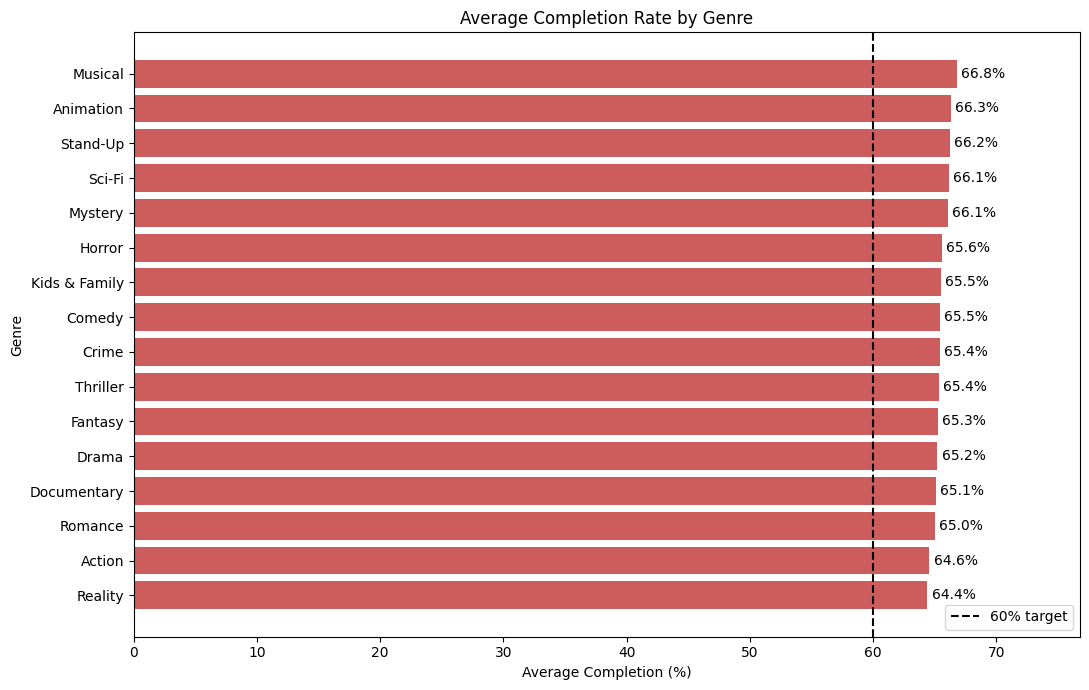

primary_genre
Musical          66.8
Animation        66.3
Stand-Up         66.2
Sci-Fi           66.1
Mystery          66.1
Horror           65.6
Kids & Family    65.5
Comedy           65.5
Crime            65.4
Thriller         65.4
Fantasy          65.3
Drama            65.2
Documentary      65.1
Romance          65.0
Action           64.6
Reality          64.4
Name: completion_pct, dtype: float64


In [38]:
completion = df.groupby("primary_genre")["completion_pct"].mean().sort_values()

plt.figure(figsize=(11, 7))
bars = plt.barh(completion.index, completion.values, color="indianred")
plt.axvline(60, color="black", linestyle="--", label="60% target")
plt.title("Average Completion Rate by Genre")
plt.xlabel("Average Completion (%)")
plt.ylabel("Genre")

# Adding data labels
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.xlim(0, completion.max() * 1.15)

plt.legend()
plt.tight_layout()

plt.savefig("09_completion_by_genre.png", dpi=150)
plt.show()

print(completion.sort_values(ascending=False).round(1))

Observation
>9.Completion Rate by Genre
<br>
Musical has the highest average completion rate at 66.8%, while Reality has the lowest at 64.4%. All genres are above the PRD's 60% target, although the differences between genres are relatively small.

## Chart 10 - Review sentiment breakdown

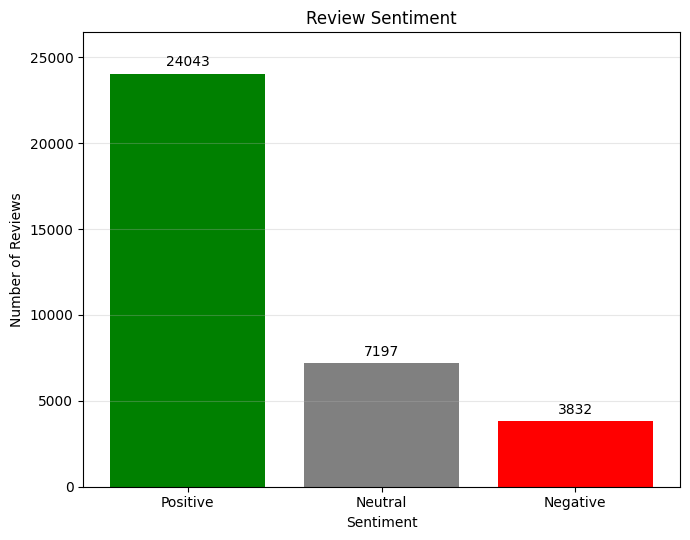

sentiment
Positive    68.6
Neutral     20.5
Negative    10.9
Name: count, dtype: float64


In [50]:
sentiment = reviews["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"])

plt.figure(figsize=(7, 5.5))
bars = plt.bar(sentiment.index, sentiment.values, color=["green", "gray", "red"])
plt.title("Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

# Adding data labels
plt.bar_label(bars, fmt="%d", padding=3)
plt.ylim(0, sentiment.max() * 1.1)

plt.tight_layout()
plt.grid(axis="y", alpha=0.3)

plt.savefig("10_review_sentiment.png", dpi=150)
plt.show()

print((sentiment / sentiment.sum() * 100).round(1))

Observation
>10.Review Sentiment Breakdown
<br>
Most reviews are Positive (68.6%), followed by Neutral (20.5%) and Negative (10.9%). This suggests generally positive subscriber feedback, though negative reviews should still be examined to identify areas for improvement.